# SlipCast: model evaluation

This notebook reproduces the numbers on SlipCast's **Model evaluation** page for the demo
project, using the same functions the API calls, and adds the charts behind them.

Two rules apply to every model:

1. **Time-based split.** Train on older tickets, test on newer ones. A random split would
   let the model learn from the future (for example, a ticket created in October helping to
   predict one from June) and would overstate accuracy. In production the model always
   predicts tickets newer than anything it trained on, so the test should too.
2. **Always a baseline.** A metric only means something next to what a trivial approach
   gets. Each model is compared with a simple, honest alternative.

Models covered: the ticket-type classifier, the slip-risk model, reference-class forecasts
and the Monte Carlo completion forecast.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="Unknown solver options")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from slipcast_data import NOW, load_demo  # first: puts backend/ on the import path
from app.services import forecast, nlp, reference_class

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

analysis = load_demo()
t = analysis.tickets
print(f"{len(t)} tickets; {t.finished.sum()} finished; {(t.kind_source == 'label').sum()} with a type label")

430 tickets; 398 finished; 347 with a type label


## The time-based split

For each model the tickets are ordered by creation date; the oldest 75% train the model
and the newest 25% test it. The chart shows where that line falls for the type classifier.

train on tickets created before 2026-09-28, test on the rest


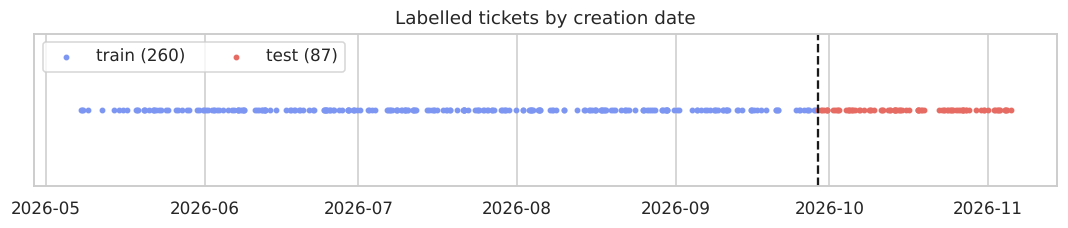

In [2]:
labelled = t[t.kind_source == "label"]
train, test, split = nlp.time_split(labelled)
fig, ax = plt.subplots(figsize=(12, 1.8))
ax.scatter(train.created_at, np.zeros(len(train)), s=8, c="#7D96F2", label=f"train ({len(train)})")
ax.scatter(test.created_at, np.zeros(len(test)), s=8, c="#E66C63", label=f"test ({len(test)})")
ax.axvline(test.created_at.min(), c="k", ls="--")
ax.set(yticks=[], title="Labelled tickets by creation date")
ax.legend(loc="upper left", ncol=2)
print(split)

## 1. Ticket-type classifier

TF-IDF over title and description (1–2 word phrases) feeding a logistic regression with
balanced class weights. **Baseline:** always predict the most common type in the training
data. Macro F1 averages F1 over the four types, so a model can't score well by ignoring
the rare ones.

In [3]:
clf = nlp.train_classifier(t)
pd.DataFrame(
    {"SlipCast": [clf["accuracy"], clf["macro_f1"]], "baseline": [clf["baseline"]["accuracy"], clf["baseline"]["macro_f1"]]},
    index=["accuracy", "macro F1"],
)

,SlipCast,baseline
accuracy,0.920,0.368
macro F1,0.894,0.134


,precision,recall,f1,support
label,,,,
bug,0.968,0.938,0.952,32
feature,0.938,0.968,0.952,31
support,1.000,0.750,0.857,12
tech_debt,0.733,0.917,0.815,12


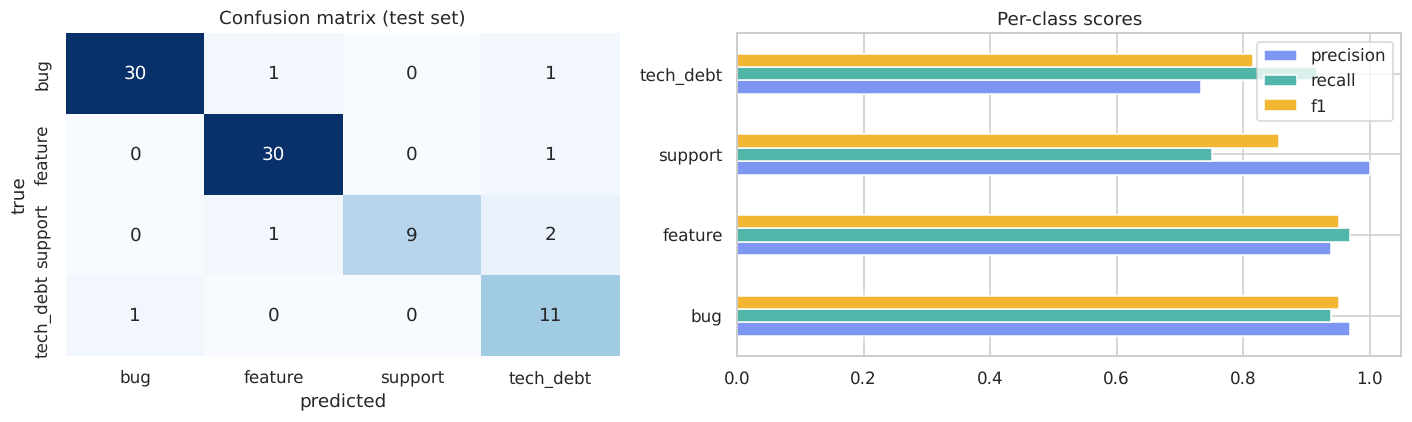

In [4]:
labels = clf["labels"]
cm = pd.DataFrame(clf["confusion_matrix"], index=labels, columns=labels)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Confusion matrix (test set)", xlabel="predicted", ylabel="true")
per = pd.DataFrame(clf["per_class"]).set_index("label")[["precision", "recall", "f1", "support"]]
per[["precision", "recall", "f1"]].plot.barh(ax=axes[1], color=["#7D96F2", "#52B5AA", "#F2B632"])
axes[1].set(xlim=(0, 1.05), title="Per-class scores", ylabel="")
plt.tight_layout()
per

In [5]:
pd.DataFrame({k: v for k, v in clf["top_terms"].items()}).T.rename(columns=lambda i: f"term {i + 1}")

,term 1,term 2,term 3,term 4,term 5,term 6
bug,error,result,saved,instead,open,instead saving
feature,admins,manage,audit log,want manage,want,need contact
support,account settings,reports problem,reply,reply customer,problem,day
tech_debt,tests,changes,issues slack,responsibilities,behaviour,dead


The diagonal dominates. Most errors fall between tech debt and the other types, which is
expected: refactoring and test work is often described in the same words as bug fixes and
features. The strongest terms are sensible (bugs talk about errors and expected results;
features about admins and managing things), a good sign the model learned the language of
each type rather than an artefact.

## 2. Slip-risk model

Logistic regression predicting whether a finished ticket was late, using only what is
known **when the ticket is created**: planned days, the owner's open tickets at that moment,
description length, risky words, quality score, unassigned, priority and type.
**Baseline:** a sensible rule of thumb, the type's median cycle time divided by the planned
days (a plan shorter than usual for that kind of work looks risky). This baseline is
deliberately strong, so beating it means the extra features add real information.

In [6]:
risk = analysis.risk.evaluation()
pd.DataFrame(
    {
        "SlipCast": [risk["roc_auc"], risk["average_precision"], risk["brier"]],
        "baseline": [risk["baseline"]["roc_auc"], risk["baseline"]["average_precision"], None],
        "chance": [0.5, risk["base_rate"], None],
    },
    index=["ROC-AUC", "average precision", "Brier score"],
)

,SlipCast,baseline,chance
ROC-AUC,0.8520,0.794,0.500
average precision,0.8350,0.783,0.478
Brier score,0.1591,NaN,NaN


trained on 276, tested on 92 (train on tickets created before 2026-09-15, test on the rest)


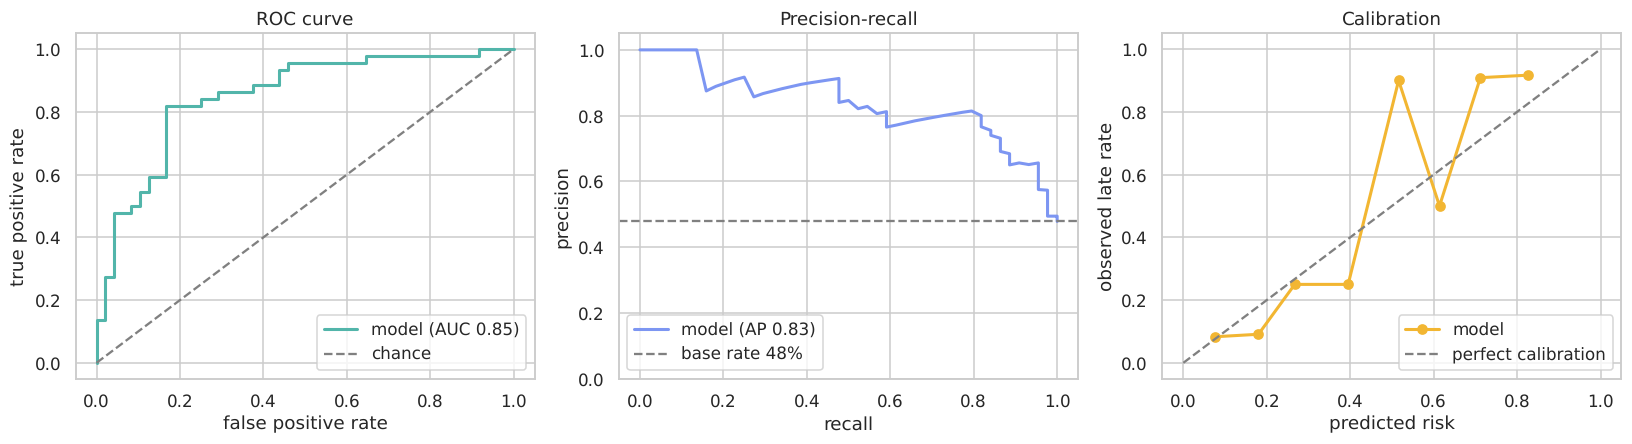

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
roc = np.array(risk["roc_curve"]); pr = np.array(risk["pr_curve"]); cal = np.array(risk["calibration"])
axes[0].plot(roc[:, 0], roc[:, 1], c="#52B5AA", lw=2, label=f"model (AUC {risk['roc_auc']:.2f})")
axes[0].plot([0, 1], [0, 1], "--", c="grey", label="chance")
axes[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate")
axes[1].plot(pr[:, 0], pr[:, 1], c="#7D96F2", lw=2, label=f"model (AP {risk['average_precision']:.2f})")
axes[1].axhline(risk["base_rate"], ls="--", c="grey", label=f"base rate {risk['base_rate']:.0%}")
axes[1].set(title="Precision-recall", xlabel="recall", ylabel="precision", ylim=(0, 1.05))
axes[2].plot(cal[:, 0], cal[:, 1], "o-", c="#F2B632", lw=2, label="model")
axes[2].plot([0, 1], [0, 1], "--", c="grey", label="perfect calibration")
axes[2].set(title="Calibration", xlabel="predicted risk", ylabel="observed late rate")
for ax in axes:
    ax.legend(loc="lower right" if ax is not axes[1] else "lower left")
plt.tight_layout()
print(f"trained on {risk['train_size']}, tested on {risk['test_size']} ({risk['split']})")

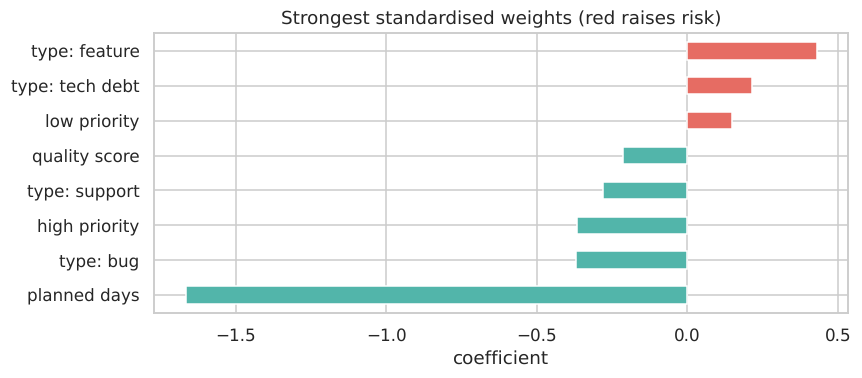

In [8]:
w = pd.DataFrame(risk["weights"]).set_index("feature").weight.sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
w.plot.barh(ax=ax, color=["#52B5AA" if v < 0 else "#E66C63" for v in w])
ax.set(title="Strongest standardised weights (red raises risk)", xlabel="coefficient", ylabel="")
plt.tight_layout()

Planned days dominate, as the exploratory notebook suggested: the shorter the plan, the
likelier the slip. Feature work and tech debt raise risk, and higher quality lowers it. The
model ranks tickets better than the baseline. Calibration is reasonable but not perfect with
a test set of this size, which is why the app shows risk as a percentage alongside its main
reasons rather than as a verdict. Each ticket's reasons come from coefficient × standardised
value, the same numbers shown here.

## 3. Reference-class forecasts

For each test ticket, find the 20 most similar tickets (TF-IDF cosine ≥ 0.15) that had
**finished before the test period began**, and predict its cycle time as their P10–P90
range. If the ranges are honest, about 80% of real outcomes should fall inside them.
**Baseline** for the middle estimate: the project-wide median cycle time.

In [9]:
rc = reference_class.evaluate(t)
pd.Series({k: rc[k] for k in ["train_size", "test_size", "evaluated", "coverage_p10_p90", "p50_mae_days"]} | {"baseline_p50_mae_days": rc["baseline"]["p50_mae_days"]})

train_size               275.00
test_size                100.00
evaluated                100.00
coverage_p10_p90           0.83
p50_mae_days               2.71
baseline_p50_mae_days      3.02
dtype: float64

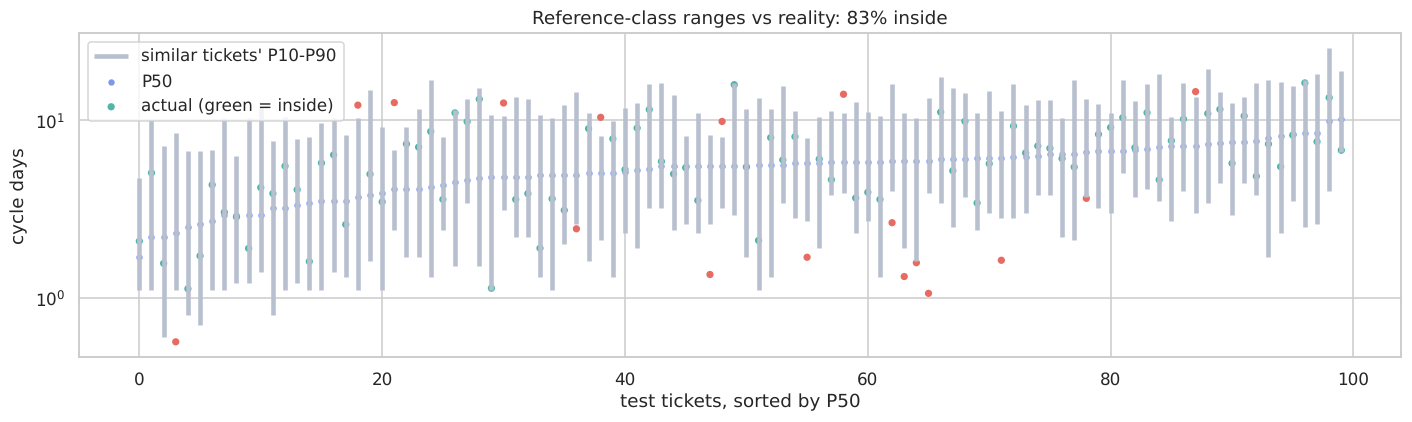

In [10]:
# Rebuild the per-ticket intervals behind the coverage number, to see them.
done = t[t.finished].sort_values("created_at")
cutoff = done.created_at.quantile(0.75)
tr = done[done.completed_at < cutoff].reset_index(drop=True)
te = done[done.created_at >= cutoff].reset_index(drop=True)
vec = reference_class.make_vectorizer()
x_tr = vec.fit_transform(reference_class.ticket_text(tr.title, tr.description))
sims = (vec.transform(reference_class.ticket_text(te.title, te.description)) @ x_tr.T).toarray()
rows = []
for i, actual in enumerate(te.cycle_days):
    ref = reference_class.summarise(sims[i], tr.cycle_days.to_numpy(), tr.late.to_numpy())
    if ref["available"]:
        rows.append({"p10": ref["p10"], "p50": ref["p50"], "p90": ref["p90"], "actual": actual})
iv = pd.DataFrame(rows).sort_values("p50").reset_index(drop=True)
iv["inside"] = iv.actual.between(iv.p10, iv.p90)
fig, ax = plt.subplots(figsize=(13, 4))
ax.vlines(iv.index, iv.p10, iv.p90, color="#B8C0D0", lw=3, label="similar tickets' P10-P90")
ax.scatter(iv.index, iv.p50, s=10, c="#7D96F2", label="P50")
ax.scatter(iv.index, iv.actual, s=14, c=iv.inside.map({True: "#52B5AA", False: "#E66C63"}), label="actual (green = inside)")
ax.set(yscale="log", xlabel="test tickets, sorted by P50", ylabel="cycle days", title=f"Reference-class ranges vs reality: {iv.inside.mean():.0%} inside")
ax.legend(loc="upper left")
plt.tight_layout()

Coverage lands close to the 80% the P10–P90 range promises, so the "Tickets like this took
X–Y days" statement in the app is honest. The middle estimate beats the project median, but
not by a lot: individual tickets are noisy, and the range, not the single number, is the
useful output.

## 4. Monte Carlo completion forecast: backtest

At each past week, using only throughput known by then, forecast how long the next batch of
tickets (about two weeks of typical work) would take, then measure how long it really took.
An 85% forecast should be met about 85% of the time.

P85 hit rate 95% over 19 replayed forecasts; P50 off by 2.2 days on average


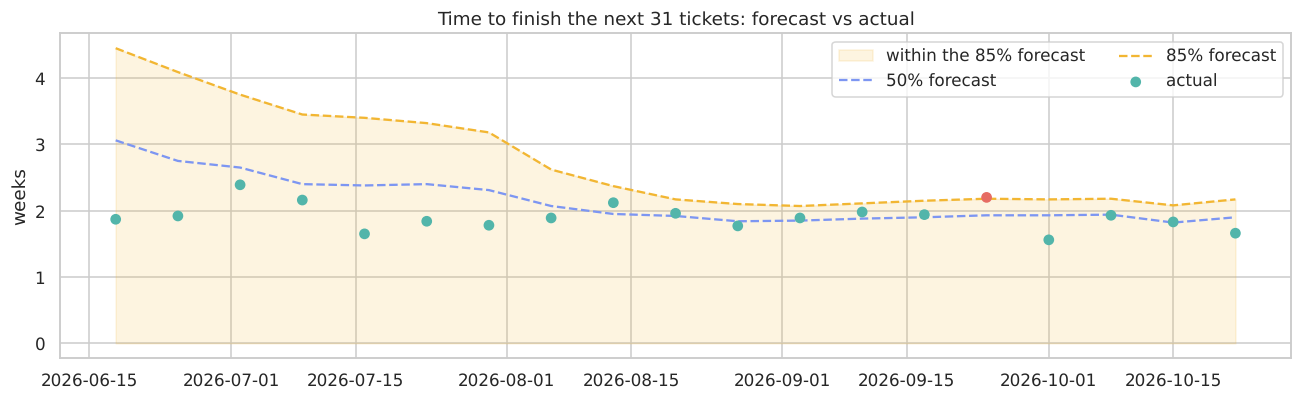

In [11]:
bt = forecast.backtest(t, NOW)
pts = pd.DataFrame(bt["points"])
pts["cutoff"] = pd.to_datetime(pts.cutoff)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.fill_between(pts.cutoff, 0, pts.p85_weeks, color="#F2B632", alpha=0.15, label="within the 85% forecast")
ax.plot(pts.cutoff, pts.p50_weeks, "--", c="#7D96F2", label="50% forecast")
ax.plot(pts.cutoff, pts.p85_weeks, "--", c="#F2B632", label="85% forecast")
ax.scatter(pts.cutoff, pts.actual_weeks, c=pts.hit_p85.map({True: "#52B5AA", False: "#E66C63"}), zorder=3, label="actual")
ax.set(ylabel="weeks", title=f"Time to finish the next {bt['batch_size']} tickets: forecast vs actual")
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()
print(f"P85 hit rate {bt['p85_hit_rate']:.0%} over {len(pts)} replayed forecasts; P50 off by {bt['p50_mean_abs_error_days']} days on average")

Early forecasts are wide because there were only a few weeks of history; they tighten as
data accumulates. The P85 line is met at or above the promised rate, so the forecast errs on
the cautious side, which is the right direction for a date someone will commit to.

## Summary

In [12]:
summary = pd.DataFrame(
    [
        ("Type classifier", "accuracy", clf["accuracy"], clf["baseline"]["accuracy"], "always the most common type"),
        ("Type classifier", "macro F1", clf["macro_f1"], clf["baseline"]["macro_f1"], "always the most common type"),
        ("Slip-risk model", "ROC-AUC", risk["roc_auc"], risk["baseline"]["roc_auc"], "type's median cycle / planned days"),
        ("Slip-risk model", "average precision", risk["average_precision"], risk["baseline"]["average_precision"], "same heuristic"),
        ("Reference class", "P10-P90 coverage", rc["coverage_p10_p90"], 0.80, "target"),
        ("Reference class", "P50 error (days)", rc["p50_mae_days"], rc["baseline"]["p50_mae_days"], "project median"),
        ("Monte Carlo", "P85 hit rate", bt["p85_hit_rate"], 0.85, "target"),
        ("Themes", "cosine silhouette", analysis.theme_result["silhouette"], None, "0.1-0.3 is typical for short text"),
    ],
    columns=["model", "metric", "SlipCast", "baseline / target", "baseline is"],
)
summary

,model,metric,SlipCast,baseline / target,baseline is
0,Type classifier,accuracy,0.920,0.368,always the most common type
1,Type classifier,macro F1,0.894,0.134,always the most common type
2,Slip-risk model,ROC-AUC,0.852,0.794,type's median cycle / planned days
3,Slip-risk model,average precision,0.835,0.783,same heuristic
4,Reference class,P10-P90 coverage,0.830,0.800,target
5,Reference class,P50 error (days),2.710,3.020,project median
6,Monte Carlo,P85 hit rate,0.947,0.850,target
7,Themes,cosine silhouette,0.212,NaN,0.1-0.3 is typical for short text


Every model beats its baseline or meets its target on data it never saw. The numbers come
from a synthetic dataset, so they show the method works rather than promise the same
accuracy on every team's data. That is why the app keeps a **forecast ledger**: it scores
every forecast it makes on each team's real tickets, so accuracy is measured per team rather
than assumed.